# 11 · La distribución normal

La densidad normal, el efecto de sus parámetros, el cálculo de probabilidades con `scipy.stats.norm`, la estandarización, la aproximación normal de la binomial y una aplicación a la diversificación de riesgo. Cierra con estimación por momentos y por máxima verosimilitud.

**Contenido**

1. La densidad normal
2. La función de distribución
3. Cálculo de probabilidades
4. Ejercicios
5. Aproximación normal de la binomial
6. Diversificación y riesgo de insolvencia
7. Estimación

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.stats import binom, norm

rng = np.random.default_rng(2026)

## 1. La densidad normal

La distribución normal se usa en ciencias naturales y sociales para modelar cantidades que resultan de sumar muchos efectos pequeños e independientes; el teorema central del límite explica por qué.

Una variable aleatoria $X$ tiene distribución normal con media $\mu\in\mathbb R$ y varianza $\sigma^2>0$, y se escribe $X\sim N(\mu,\sigma^2)$, si tiene densidad

$$f(x)=\frac{1}{\sigma\sqrt{2\pi}}\exp\left\{-\frac{(x-\mu)^2}{2\sigma^2}\right\},\qquad x\in\mathbb R.$$

Su gráfica es la **campana de Gauss**. Sus propiedades:

1. $f(x)>0$ para todo $x$;
2. $f$ es infinitamente derivable;
3. $f$ es simétrica respecto de $\mu$, donde alcanza su máximo global $\frac{1}{\sigma\sqrt{2\pi}}$;
4. tiene puntos de inflexión en $\mu\pm\sigma$;
5. $f(x)\to0$ más rápido que cualquier potencia de $1/|x|$ cuando $|x|\to\infty$;
6. $\int_{\mathbb R}f=1$.

**Ejercicio.** Investiga fenómenos reales que se modelan con la distribución normal, y otros en los que el modelo normal falla (colas pesadas).

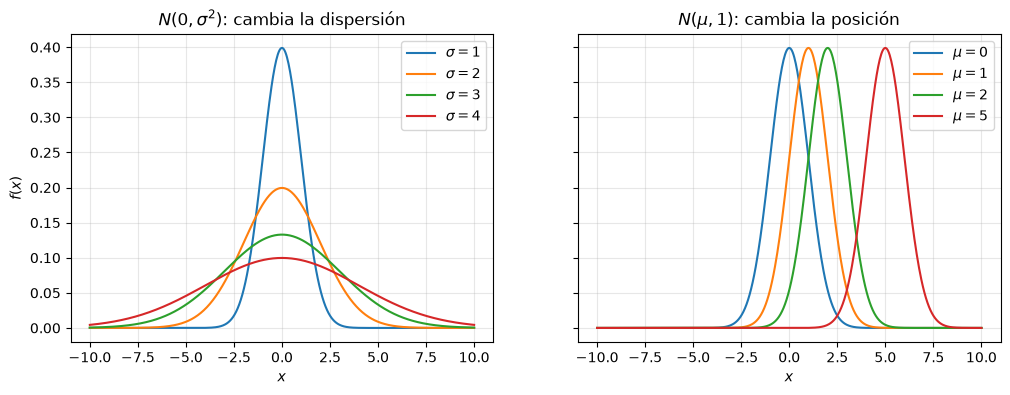

In [2]:
x = np.linspace(-10, 10, 500)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for s in [1, 2, 3, 4]:
    axes[0].plot(x, norm.pdf(x, scale=s), label=rf"$\sigma={s}$")
axes[0].set_title(r"$N(0,\sigma^2)$: cambia la dispersión")
for m in [0, 1, 2, 5]:
    axes[1].plot(x, norm.pdf(x, loc=m), label=rf"$\mu={m}$")
axes[1].set_title(r"$N(\mu,1)$: cambia la posición")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
    ax.set_xlabel("$x$")
axes[0].set_ylabel("$f(x)$")
plt.show()

**Versión interactiva.** Con los deslizadores (Altair) cambia $\mu$ y $\sigma$; la curva gris es $N(0,1)$ como referencia.

In [3]:
import altair as alt
import pandas as pd

x = np.linspace(-10, 10, 401)
mu_sel = alt.param(name="mu", value=0, bind=alt.binding_range(min=-5, max=5, step=0.5, name="μ: "))
sigma_sel = alt.param(name="sigma", value=1, bind=alt.binding_range(min=0.5, max=4, step=0.1, name="σ: "))
base = alt.Chart(pd.DataFrame({"x": x})).transform_calculate(
    estandar="exp(-datum.x * datum.x / 2) / sqrt(2 * PI)",
    f="exp(-pow((datum.x - mu) / sigma, 2) / 2) / (sigma * sqrt(2 * PI))",
)
(base.mark_line(color="lightgray").encode(x="x:Q", y=alt.Y("estandar:Q", title="f(x)", scale=alt.Scale(domain=[0, 0.8])))
 + base.mark_area(opacity=0.5).encode(x="x:Q", y="f:Q")
).add_params(mu_sel, sigma_sel).properties(width=520, height=240, title="Densidad N(μ, σ²)")

alt.LayerChart(...)

## 2. La función de distribución

Para $a<b$, $\mathbb P(a\le X\le b)$ es el área bajo $f$ sobre $[a,b]$. La **función de distribución** (cdf) y la **función de supervivencia** (sf) son

$$\mathrm{cdf}(x)=\mathbb P(X\le x)=\int_{-\infty}^xf(t)\,dt,\qquad \mathrm{sf}(x)=\mathbb P(X>x)=1-\mathrm{cdf}(x),$$

y $\mathbb P(a\le X\le b)=\mathrm{cdf}(b)-\mathrm{cdf}(a)$. La función inversa de la cdf es `norm.ppf` (los cuantiles).

Para no repetir código, una función dibuja la densidad y sombrea una región.

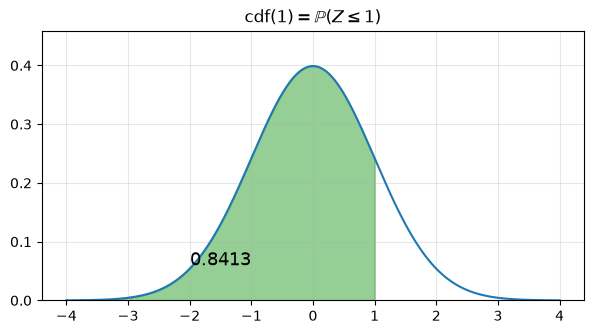

In [4]:
def sombrea(mu=0, sigma=1, a=-np.inf, b=np.inf, ax=None, titulo=None):
    """Dibuja la densidad N(mu, sigma^2) y sombrea P(a < X < b)."""
    ax = ax or plt.subplots(figsize=(7, 3.5))[1]
    x = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 600)
    ax.plot(x, norm.pdf(x, mu, sigma), color="tab:blue")
    xa, xb = max(a, x[0]), min(b, x[-1])
    px = np.linspace(xa, xb, 300)
    ax.fill_between(px, norm.pdf(px, mu, sigma), alpha=0.5, color="tab:green")
    prob = norm.cdf(b, mu, sigma) - norm.cdf(a, mu, sigma)
    ax.text((xa + xb) / 2, norm.pdf(mu, mu, sigma) * 0.15, f"{prob:.4f}", ha="center", fontsize=13)
    ax.set_title(titulo or rf"$N({mu},{sigma}^2)$")
    ax.set_ylim(0, norm.pdf(mu, mu, sigma) * 1.15)
    ax.grid(alpha=0.3)
    return prob

sombrea(b=1, titulo=r"$\mathrm{cdf}(1)=\mathbb{P}(Z\leq 1)$")
plt.show()

## 3. Cálculo de probabilidades

**Estandarización.** Si $X\sim N(\mu,\sigma^2)$, entonces $Z=\dfrac{X-\mu}{\sigma}\sim N(0,1)$, así que

$$\mathbb P(X\le x)=\Phi\Big(\frac{x-\mu}{\sigma}\Big),$$

donde $\Phi$ es la función de distribución de la normal estándar. En `scipy`, `norm.cdf(x, loc=mu, scale=sigma)`; el parámetro `scale` es la **desviación estándar** $\sigma$, no la varianza.

**a)** $\mathbb P(X<2)$ con $X\sim N(3,2^2)$:

0.3085375387259869 = 0.3085375387259869


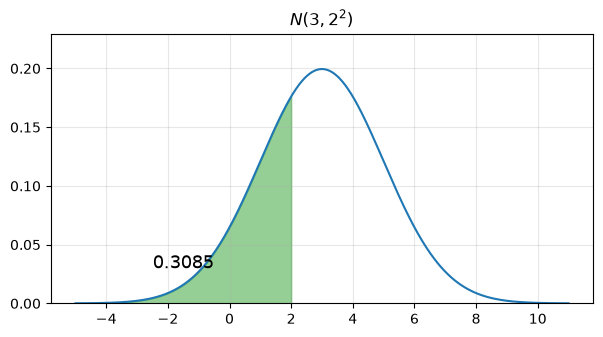

In [5]:
p = norm.cdf(2, loc=3, scale=2)
print(p, "=", norm.cdf((2 - 3) / 2))
sombrea(3, 2, b=2)
plt.show()

**b)** $\mathbb P(0.5<X<2)$ con $X\sim N(1,2^2)$, y lo mismo si la **varianza** es $2$, es decir $\sigma=\sqrt2$:

σ = 2:   0.2901687869569368
σ = √2:  0.3984131339906417


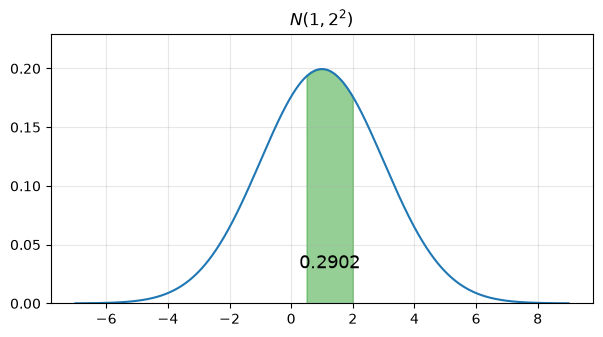

In [6]:
print("σ = 2:  ", norm(1, 2).cdf(2) - norm(1, 2).cdf(0.5))
print("σ = √2: ", norm(1, np.sqrt(2)).cdf(2) - norm(1, np.sqrt(2)).cdf(0.5))
sombrea(1, 2, 0.5, 2)
plt.show()

**c)** $\mathbb P(X>4)$ con $X\sim N(3,2^2)$, con `norm.sf`, y su complemento:

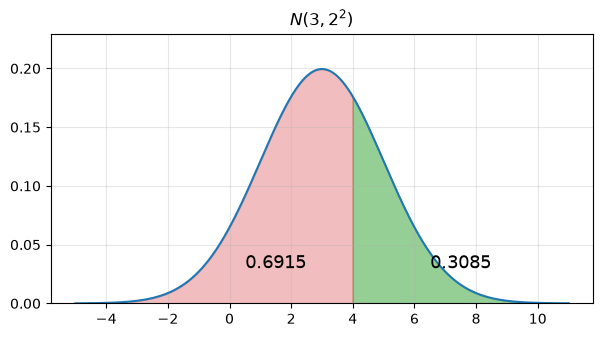

0.3085375387259869 0.3085375387259869


In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
p_mayor = sombrea(3, 2, a=4, ax=ax)
x = np.linspace(-5, 4, 300)
ax.fill_between(x, norm.pdf(x, 3, 2), alpha=0.3, color="tab:red")
ax.text(1.5, 0.03, f"{1 - p_mayor:.4f}", fontsize=13, ha="center")
plt.show()
print(norm.sf(4, loc=3, scale=2), 1 - norm.cdf(4, loc=3, scale=2))

**La regla 68–95–99.7.** $\mathbb P(|X-\mu|<k\sigma)=2\Phi(k)-1$ no depende de $\mu$ ni de $\sigma$:

In [8]:
{k: round(2 * norm.cdf(k) - 1, 4) for k in (1, 2, 3)}

{1: np.float64(0.6827), 2: np.float64(0.9545), 3: np.float64(0.9973)}

## 4. Ejercicios

**Ejercicio 1.** Si $Z\sim N(0,1)$, encuentra $\mathbb P(-1.93<Z<1.93)$.

**Solución.** $\mathbb P(-1.93<Z<1.93)=2\Phi(1.93)-1$.

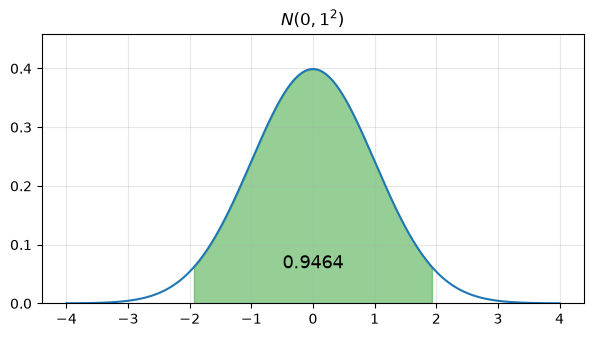

np.float64(0.9463931622458901)

In [9]:
sombrea(0, 1, -1.93, 1.93)
plt.show()
2 * norm.cdf(1.93) - 1

**Ejercicio 2.** Las estaturas de las mujeres de cierto país siguen una distribución normal con media $172$ cm y desviación estándar $5$ cm. Se elige una persona al azar. Calcula la probabilidad de que

1. mida al menos $176$ cm;
2. no mida más de $180$ cm;
3. mida entre $168$ y $174$ cm.

**Solución.** Sea $X\sim N(172,5^2)$.

1. $\mathbb P(X\ge176)=\mathbb P(Z\ge 0.8)$.
2. $\mathbb P(X\le180)=\mathbb P(Z\le1.6)$.
3. $\mathbb P(168\le X\le174)=\mathbb P(-0.8\le Z\le 0.4)$.

1. 0.2118553985833967 0.2118553985833967
2. 0.945200708300442 0.945200708300442
3. 0.4435663430269275 0.4435663430269275


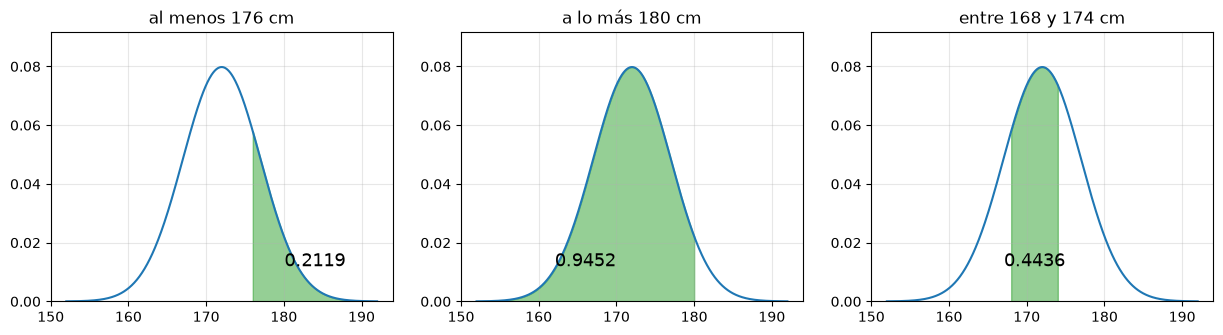

In [10]:
X = norm(172, 5)
print("1.", X.sf(176), norm.sf(0.8))
print("2.", X.cdf(180), norm.cdf(1.6))
print("3.", X.cdf(174) - X.cdf(168), norm.cdf(0.4) - norm.cdf(-0.8))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
sombrea(172, 5, a=176, ax=axes[0], titulo="al menos 176 cm")
sombrea(172, 5, b=180, ax=axes[1], titulo="a lo más 180 cm")
sombrea(172, 5, 168, 174, ax=axes[2], titulo="entre 168 y 174 cm")
plt.show()

## 5. Aproximación normal de la binomial

Se lanzan $1000$ monedas con $\mathbb P(\text{sol})=0.3$. Sea $Y$ el número de soles. Usando el teorema central del límite, estima $\mathbb P(Y>50)$, $\mathbb P(100<Y<300)$ y $\mathbb P(Y>400)$.

**Solución.** $Y\sim\mathrm{Bin}(1000,0.3)$, con $\mathbb E[Y]=300$ y $\operatorname{Var}(Y)=1000(0.3)(0.7)=210$. Por el teorema de De Moivre–Laplace,

$$\frac{Y-300}{\sqrt{210}}\approx N(0,1).$$

Así $\mathbb P(Y>50)\approx\mathbb P(Z>-17.25)\approx 1$, $\mathbb P(100<Y<300)\approx\mathbb P(-13.80<Z<0)\approx\frac12$ y $\mathbb P(Y>400)\approx\mathbb P(Z>6.90)\approx 2.6\times10^{-12}$.

Comparamos con las probabilidades exactas de la binomial. La **corrección por continuidad** (sumar o restar $\frac12$ en los extremos) mejora la aproximación, porque $Y$ toma valores enteros.

In [11]:
n, p = 1000, 0.3
mu, sd = n * p, np.sqrt(n * p * (1 - p))
Z = norm(mu, sd)

filas = [
    ("P(Y > 50)", binom.sf(50, n, p), Z.sf(50), Z.sf(50.5)),
    ("P(100 < Y < 300)", binom.cdf(299, n, p) - binom.cdf(100, n, p), Z.cdf(300) - Z.cdf(100), Z.cdf(299.5) - Z.cdf(100.5)),
    ("P(Y > 400)", binom.sf(400, n, p), Z.sf(400), Z.sf(400.5)),
]
print(f"{'evento':<18}{'exacta':>14}{'normal':>14}{'normal corr.':>14}")
for nombre, *valores in filas:
    print(f"{nombre:<18}" + "".join(f"{v:14.4g}" for v in valores))

evento                    exacta        normal  normal corr.
P(Y > 50)                      1             1             1
P(100 < Y < 300)          0.4881           0.5        0.4862
P(Y > 400)              7.03e-12     2.588e-12     2.029e-12


La aproximación de $\mathbb P(100<Y<300)$ por $\frac12$ comete un error de $0.012$, casi la mitad de $\mathbb P(Y=300)\approx 0.0275$: la normal reparte la masa del valor $300$ a ambos lados de la media. Con la corrección por continuidad el error baja a $0.002$. En la cola lejana, $\mathbb P(Y>400)$, ambas aproximaciones aciertan el orden de magnitud pero tienen un error relativo grande: el teorema central del límite controla errores absolutos, no relativos.

Una simulación confirma la escala del problema: las sumas se concentran en $300\pm3\sqrt{210}\approx300\pm43$.

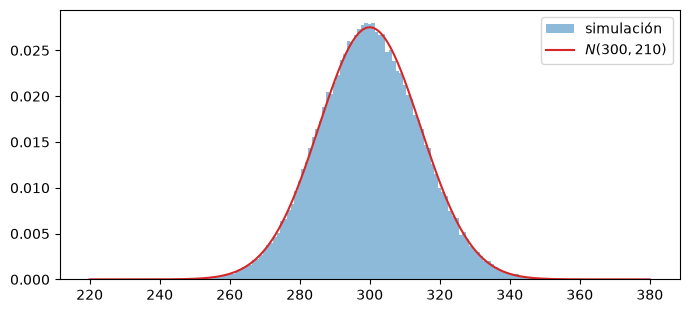

media simulada: 300.02366   varianza simulada: 209.7


In [12]:
Y = rng.binomial(n, p, size=100_000)
t = np.arange(220, 381)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(Y, bins=np.arange(219.5, 381.5), density=True, alpha=0.5, label="simulación")
ax.plot(t, norm.pdf(t, mu, sd), color="tab:red", label=r"$N(300, 210)$")
ax.legend()
plt.show()
print("media simulada:", Y.mean(), "  varianza simulada:", round(Y.var(), 1))

## 6. Diversificación y riesgo de insolvencia

Un banco de inversión administra mil millones de dólares en activos ligados al mercado de vivienda. Como invierte con dinero prestado, su capital propio es de $50$ millones ($5\%$): si pierde más del $5\%$, es insolvente.

**a)** El banco invierte todo en un solo activo cuyo rendimiento anual (en puntos porcentuales) es $R\sim N(7,10^2)$. ¿Cuál es la probabilidad de insolvencia?

**b)** El banco reparte la inversión en $20$ activos con rendimientos $R_i\sim N(7,10^2)$ **independientes**, de modo que su rendimiento es $\bar R=(R_1+\cdots+R_{20})/20$. ¿Cuál es ahora la probabilidad de insolvencia?

**Solución.** a) $\mathbb P(R<-5)=\Phi(-1.2)\approx0.115$: más de una vez cada nueve años.

b) $\bar R\sim N(7,\,100/20)=N(7,5)$, de modo que $\mathbb P(\bar R<-5)=\Phi(-12/\sqrt5)\approx 4\times10^{-8}$.

In [13]:
print("a)", norm.cdf(-5, loc=7, scale=10))
print("b)", norm.cdf(-5, loc=7, scale=np.sqrt(100 / 20)))

a) 0.11506967022170822
b) 4.012555633463782e-08


El supuesto de independencia es crucial. Si cada par de activos tiene correlación $\rho$, entonces $\operatorname{Var}(\bar R)=\frac{100}{20}\big(1+19\rho\big)$, y la diversificación protege mucho menos. Los activos hipotecarios de distintas regiones resultaron fuertemente correlacionados en la crisis de 2008.

In [14]:
for rho in [0, 0.1, 0.3, 0.5, 1]:
    var = 100 / 20 * (1 + 19 * rho)
    print(f"ρ = {rho:>3}:  P(insolvencia) = {norm.cdf(-5, 7, np.sqrt(var)):.3g}")

ρ =   0:  P(insolvencia) = 4.01e-08
ρ = 0.1:  P(insolvencia) = 0.000813
ρ = 0.3:  P(insolvencia) = 0.0191
ρ = 0.5:  P(insolvencia) = 0.0488
ρ =   1:  P(insolvencia) = 0.115


## 7. Estimación

**Momentos muestrales.** El tiempo (en minutos) que toma una tarea en una fábrica se observa en una muestra: $18, 21, 17, 16, 24, 20$. La media muestral es $\bar x$; la **varianza muestral** insesgada divide entre $n-1$:

$$s^2=\frac{1}{n-1}\sum_{i=1}^n(x_i-\bar x)^2.$$

En NumPy, `var()` divide entre $n$ por omisión; `var(ddof=1)` divide entre $n-1$.

In [15]:
muestra = np.array([18, 21, 17, 16, 24, 20])
print(f"media = {muestra.mean():.4f}")
print(f"varianza muestral s² = {muestra.var(ddof=1):.4f}   (dividiendo entre n: {muestra.var():.4f})")
print(f"desviación estándar muestral s = {muestra.std(ddof=1):.4f}")

media = 19.3333
varianza muestral s² = 8.6667   (dividiendo entre n: 7.2222)
desviación estándar muestral s = 2.9439


**Máxima verosimilitud.** Sea $X\sim\mathrm{Bin}(3,\theta)$ con $\theta$ desconocido: $X$ cuenta los éxitos en $3$ ensayos independientes con probabilidad de éxito $\theta$. Con la muestra $(1,3,2,2)$, la verosimilitud es

$$L(\theta)=\binom31\binom33\binom32\binom32\,\theta^{8}(1-\theta)^{4},$$

y el estimador de máxima verosimilitud maximiza $\log L$.

In [16]:
theta = sp.symbols("theta", positive=True)
muestra = [1, 3, 2, 2]
L = sp.Mul(*[sp.binomial(3, x) * theta**x * (1 - theta) ** (3 - x) for x in muestra])
logL = sp.expand_log(sp.log(L), force=True)
display(L, logL)
sp.solve(sp.diff(logL, theta), theta)

27*theta**8*(1 - theta)**4

8*log(theta) + 4*log(1 - theta) + 3*log(3)

[2/3]

$\hat\theta=\frac{8}{12}=\frac23$: la proporción total de éxitos $\frac{\sum x_i}{3n}$, que también es el estimador por momentos ($\mathbb E[X]=3\theta$).